# Notebook A — Chuẩn Bị Dữ Liệu
## Phát Hiện Gian Lận Thẻ Tín Dụng Bằng Học Máy và Đánh Giá Tổng Quát Hóa trên Dữ Liệu Chưa Thấy

---

## Mục Tiêu Dự Án

Notebook này chuẩn bị dữ liệu cho nghiên cứu phát hiện gian lận thẻ tín dụng.
Ba câu hỏi nghiên cứu (Research Questions) được trả lời trong Notebook B.

| # | Research Question |
|---|---|
| **RQ1** | **Which class imbalance handling technique is most effective for credit card fraud detection?** |
| **RQ2** | **Which machine learning model and classification threshold provide the best trade-off between fraud detection and false positive reduction?** |
| **RQ3** | **How well does the selected machine learning model, with its optimized classification threshold, generalize to previously unseen transaction data?** |

---

## Bối Cảnh: Phát Hiện Gian Lận Thẻ Tín Dụng

Gian lận thẻ tín dụng gây thiệt hại hàng chục tỷ đô-la mỗi năm.
Hệ thống phát hiện tự động cần phân biệt giao dịch hợp lệ và gian lận trong thời gian thực.

**Thách thức chính: Mất cân bằng lớp (Class Imbalance)**

Chỉ một phần rất nhỏ giao dịch là gian lận (thường dưới 0.2%).
Một mô hình đơn giản dự đoán tất cả là 'hợp lệ' vẫn đạt accuracy > 99%,
nhưng hoàn toàn thất bại trong việc phát hiện gian lận.
Vì vậy, cần các chiến lược xử lý mất cân bằng và các độ đo phù hợp như F2, Average Precision.

---

## Quy Trình Nghiên Cứu

```
Du lieu tho (creditcard.csv)
        |
        v
[Notebook A] Kiem tra chat luong -> EDA -> Chia tap du lieu
        |
        v
 data/processed/ (X_train, y_train, X_val, y_val, X_test, y_test, manifest.json)
        |
        v
[Notebook B] RQ1: So sanh xu ly mat can bang
           -> RQ2: So sanh mo hinh + toi uu nguong phan loai
           -> RQ3: Danh gia cuoi tren tap test chua thay
        |
        v
 results/ (bang ket qua, hinh ve, bao cao)
```

**Notebook A** (file này): Nạp dữ liệu, kiểm tra chất lượng, phân tích khám phá (EDA),
chia tập train/validation/test, lưu artifacts cho Notebook B.

**Notebook B**: Chạy thí nghiệm trả lời RQ1–RQ3, tạo kết quả cuối cùng.

> **Quan trọng:** Tập test **không được chạm** cho đến khi cấu hình mô hình cuối
> được đóng băng hoàn toàn trong Notebook B.

---
## Phần 1 — Môi Trường và Cấu Hình

Trước khi bắt đầu, ta kiểm tra phiên bản Python và các thư viện cần thiết.
Nếu thiếu thư viện, notebook hiển thị lệnh cài đặt rõ ràng.

In [1]:
# Kiem tra moi truong
import sys
print(f'Python: {sys.version}')

REQUIRED = {
    "pandas":     "pandas",
    "numpy":      "numpy",
    "matplotlib": "matplotlib",
    "seaborn":    "seaborn",
    "sklearn":    "scikit-learn",
    "imblearn":   "imbalanced-learn",
    "joblib":     "joblib",
}

missing = []
for pkg, install_name in REQUIRED.items():
    try:
        __import__(pkg)
        print(f'  ok {pkg}')
    except ImportError:
        print(f'  MISSING {pkg}  ->  pip install {install_name}')
        missing.append(install_name)

if missing:
    raise EnvironmentError(
        f'Thieu thu vien: {missing}. '
        'Vui long chay pip install tuong ung o tren truoc khi tiep tuc.'
    )
else:
    print('\nTat ca thu vien san sang.')

Python: 3.13.16 (tags/v3.13.16:cbc944f, Sep 30 2026, 19:17:50) [MSC v.1944 64 bit (AMD64)]
  ok pandas
  ok numpy
  ok matplotlib
  ok seaborn
  ok sklearn
  ok imblearn
  ok joblib

Tat ca thu vien san sang.


### 1.2 Import Thư Viện và Khai Báo Hằng Số

| Biến | Ý nghĩa |
|---|---|
| `RANDOM_SEED` | Hạt giống ngẫu nhiên cố định — đảm bảo kết quả tái lặp |
| `TARGET_COL` | Tên cột nhãn mục tiêu (`Class`: 0 = hợp lệ, 1 = gian lận) |
| `DATA_PATH` | Đường dẫn tương đối đến file CSV nguồn |
| `PROCESSED_DIR` | Thư mục lưu dữ liệu đã xử lý |
| `TRAIN_RATIO` | Tỉ lệ dữ liệu dành cho huấn luyện (70%) |
| `VAL_RATIO` | Tỉ lệ dữ liệu dành cho kiểm định nội bộ (15%) |
| `TEST_RATIO` | Tỉ lệ dữ liệu dành cho đánh giá cuối (15%) |
| `FIGURES_EXP` | Thư mục lưu hình vẽ khám phá (exploratory) |
| `FIGURES_PAPER` | Thư mục lưu hình vẽ bài báo (paper-ready) |

In [2]:
import json
import hashlib
import warnings
import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from sklearn.model_selection import train_test_split

warnings.filterwarnings('ignore', category=FutureWarning)
matplotlib.rcParams.update({
    "figure.dpi": 120,
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# Dinh nghia duong dan goc du an (PROJECT_ROOT) bang pathlib.Path
PROJECT_ROOT = Path(r"C:\Users\lmlmdf404\Desktop\credit_card_fraud_project")
if not PROJECT_ROOT.exists():
    for parent in [Path.cwd()] + list(Path.cwd().parents):
        if (parent / 'data').is_dir() and (parent / 'notebooks').is_dir():
            PROJECT_ROOT = parent
            break

print(f'Project root: {PROJECT_ROOT}')

# Hang so cau hinh
RANDOM_SEED   = 42          # Hat giong ngau nhien — dam bao tai lap
TARGET_COL    = "Class"     # Ten cot nhan
TRAIN_RATIO   = 0.70        # 70% huan luyen
VAL_RATIO     = 0.15        # 15% kiem dinh
TEST_RATIO    = 0.15        # 15% danh gia cuoi
assert abs(TRAIN_RATIO + VAL_RATIO + TEST_RATIO - 1.0) < 1e-9, 'Ti le phai cong lai bang 1'

# Cac thu muc du an
NOTEBOOK_DIR   = PROJECT_ROOT / 'notebooks'
RAW_DATA_DIR   = PROJECT_ROOT / 'data' / 'raw'
PROCESSED_DIR  = PROJECT_ROOT / 'data' / 'processed'
FIGURES_EXP    = PROJECT_ROOT / 'results' / 'figures' / 'exploratory'
FIGURES_PAPER  = PROJECT_ROOT / 'results' / 'figures' / 'paper'
TABLES_DIR     = PROJECT_ROOT / 'results' / 'tables'
TABLES_PAPER   = PROJECT_ROOT / 'results' / 'tables' / 'paper'

# Tao thu muc neu chua co
for d in [RAW_DATA_DIR, PROCESSED_DIR, FIGURES_EXP, FIGURES_PAPER, TABLES_DIR, TABLES_PAPER]:
    d.mkdir(parents=True, exist_ok=True)

# Tu dong phat hien va chon file dataset CSV trong RAW_DATA_DIR (khong hardcode gia dinh)
csv_candidates = list(RAW_DATA_DIR.glob("*.csv"))
if not csv_candidates:
    DATA_PATH = RAW_DATA_DIR / "creditcard.csv"
else:
    # Tim file co chua cot TARGET_COL ('Class') hoac uu tien creditcard.csv
    DATA_PATH = None
    for c in csv_candidates:
        if c.name.lower() == "creditcard.csv":
            DATA_PATH = c
            break
    if DATA_PATH is None:
        for c in csv_candidates:
            try:
                sample_cols = pd.read_csv(c, nrows=1).columns
                if TARGET_COL in sample_cols:
                    DATA_PATH = c
                    break
            except Exception:
                continue
    if DATA_PATH is None:
        DATA_PATH = csv_candidates[0]

print(f'Thu muc du lieu tho:  {RAW_DATA_DIR}')
print(f'File dataset duoc chon: {DATA_PATH.name} (tai {DATA_PATH})')
print(f'Du lieu da xu ly:     {PROCESSED_DIR}')
print(f'Random seed:          {RANDOM_SEED}')


Project root: C:\Users\lmlmdf404\Desktop\credit_card_fraud_project
Thu muc du lieu tho:  C:\Users\lmlmdf404\Desktop\credit_card_fraud_project\data\raw
File dataset duoc chon: creditcard.csv (tai C:\Users\lmlmdf404\Desktop\credit_card_fraud_project\data\raw\creditcard.csv)
Du lieu da xu ly:     C:\Users\lmlmdf404\Desktop\credit_card_fraud_project\data\processed
Random seed:          42


---
## Phần 2 — Nạp Dữ Liệu

Ta kiểm tra file tồn tại, sau đó đọc và xác nhận cấu trúc cơ bản.
Nếu file CSV không tồn tại, notebook hiển thị hướng dẫn rõ ràng.

In [3]:
# 2.1 Kiem tra file ton tai
if not DATA_PATH.exists():
    raise FileNotFoundError(
        '\n' + '='*60 + '\n'
        'THIEU FILE DU LIEU!\n'
        + '='*60 + '\n'
        f'Khong tim thay dataset CSV tai:\n'
        f'  {DATA_PATH}\n\n'
        f'Hanh dong can lam:\n'
        f'  1. Tai dataset tai: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud/data\n'
        f'  2. Giai nen va dat file CSV vao thu muc:\n'
        f'     {RAW_DATA_DIR}\n'
        f'  3. Chay lai notebook nay tu dau.\n'
        + '='*60 + '\n'
    )

print(f'ok File tim thay: {DATA_PATH.name}')
print(f'  Duong dan: {DATA_PATH}')
print(f'  Kich thuoc: {DATA_PATH.stat().st_size / 1e6:.1f} MB')

# 2.2 Tinh checksum MD5
def md5_checksum(path, chunk_size=1 << 20):
    """Tinh MD5 cua file de kiem tra tinh nguyen ven."""
    h = hashlib.md5()
    with open(path, 'rb') as f:
        while True:
            chunk = f.read(chunk_size)
            if not chunk:
                break
            h.update(chunk)
    return h.hexdigest()

checksum = md5_checksum(DATA_PATH)
print(f'  MD5 checksum: {checksum}')


ok File tim thay: creditcard.csv
  Duong dan: C:\Users\lmlmdf404\Desktop\credit_card_fraud_project\data\raw\creditcard.csv
  Kich thuoc: 150.8 MB
  MD5 checksum: e90efcb83d69faf99fcab8b0255024de


In [4]:
# 2.3 Doc du lieu
df = pd.read_csv(DATA_PATH)

print(f'Kich thuoc dataset: {df.shape[0]:,} dong x {df.shape[1]} cot')
print(f'\nTen cot ({df.shape[1]} cot):')
print(list(df.columns))

Kich thuoc dataset: 284,807 dong x 31 cot

Ten cot (31 cot):
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


In [5]:
# 2.4 Kiem tra cot muc tieu va cac cot bat buoc
# Du lieu khong hop le ma notebook chua co quy tac xu ly thi dung bang loi, khong chi in canh bao.
required_cols = [TARGET_COL, 'Time', 'Amount']
missing_cols = [c for c in required_cols if c not in df.columns]
if missing_cols:
    raise KeyError(f'Thieu cot bat buoc: {missing_cols}')

n_null_label = int(df[TARGET_COL].isnull().sum())
if n_null_label > 0:
    raise ValueError(f'Cot {TARGET_COL} co {n_null_label} gia tri thieu. Can xu ly truoc khi chay tiep.')

unique_labels = sorted(df[TARGET_COL].unique().tolist())
print(f'Gia tri duy nhat trong Class: {unique_labels}')

extra = [v for v in unique_labels if v not in [0, 1]]
if extra:
    raise ValueError(f'Cot {TARGET_COL} co gia tri khong hop le (chi chap nhan 0 va 1): {extra}')
print('ok Cot Class chua dung nhan nhi phan {0, 1}')

# So sanh voi thong ke cua ban dataset Kaggle goc (chi canh bao: dataset khac van co the hop le)
EXPECTED_TOTAL = 284807
EXPECTED_FRAUD = 492
if len(df) != EXPECTED_TOTAL:
    print(f'CANH BAO: So dong khac du kien ({len(df):,} vs {EXPECTED_TOTAL:,})')
if (df[TARGET_COL] == 1).sum() != EXPECTED_FRAUD:
    print(f'CANH BAO: So fraud khac du kien ({(df[TARGET_COL]==1).sum()} vs {EXPECTED_FRAUD})')


Gia tri duy nhat trong Class: [0, 1]
ok Cot Class chua dung nhan nhi phan {0, 1}


In [6]:
# 2.5 Thong tin kieu du lieu va thong ke tom tat
print('=== Kieu du lieu ===')
print(df.dtypes.to_string())

print('\n=== 5 dong dau ===')
display(df.head())

print('\n=== 5 dong cuoi ===')
display(df.tail())

print('\n=== Thong ke tom tat (mot so cot dai dien) ===')
display(df[["Time", "Amount", "V1", "V14", "V17", TARGET_COL]].describe().round(3))

=== Kieu du lieu ===
Time      float64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class       int64

=== 5 dong dau ===


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0



=== 5 dong cuoi ===


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0
284806,172792.0,-0.533413,-0.189733,0.703337,-0.506271,-0.012546,-0.649617,1.577006,-0.414650,0.486180,...,0.261057,0.643078,0.376777,0.008797,-0.473649,-0.818267,-0.002415,0.013649,217.00,0



=== Thong ke tom tat (mot so cot dai dien) ===


,Time,Amount,V1,V14,V17,Class
count,284807.000,284807.000,284807.000,284807.000,284807.000,284807.000
mean,94813.860,88.350,0.000,0.000,-0.000,0.002
std,47488.146,250.120,1.959,0.959,0.849,0.042
min,0.000,0.000,-56.408,-19.214,-25.163,0.000
25%,54201.500,5.600,-0.920,-0.426,-0.484,0.000
50%,84692.000,22.000,0.018,0.051,-0.066,0.000
75%,139320.500,77.165,1.316,0.493,0.400,0.000
max,172792.000,25691.160,2.455,10.527,9.254,1.000


---
## Phần 3 — Đánh Giá Chất Lượng Dữ Liệu

Trước khi phân tích hay xây dựng mô hình, ta kiểm tra các vấn đề chất lượng phổ biến:
giá trị thiếu, dòng trùng lặp, giá trị vô hạn, nhãn không hợp lệ và cột không phải số.

Giá trị thiếu, giá trị vô hạn, nhãn ngoài {0, 1} và cột không phải số chưa có quy tắc xử lý trong notebook này,
nên khi gặp chúng code dừng bằng lỗi thay vì in cảnh báo rồi chạy tiếp. Riêng dòng trùng lặp có quy tắc xử lý được nêu ở mục 3.3.


In [7]:
# 3.1 Gia tri thieu (Missing values)
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(4)
missing_df = pd.DataFrame({"Missing": missing, "Missing_pct": missing_pct})
missing_df = missing_df[missing_df["Missing"] > 0]

if missing_df.empty:
    print('ok Khong co gia tri thieu trong bat ky cot nao.')
else:
    display(missing_df)
    raise ValueError(
        f'Co gia tri thieu o {len(missing_df)} cot (xem bang tren). '
        'Notebook chua co quy tac xu ly (xoa dong hay dien gia tri), can quyet dinh truoc khi chay tiep.'
    )


ok Khong co gia tri thieu trong bat ky cot nao.


In [8]:
# 3.2 Dong trung lap (Duplicate rows)
dup_mask = df.duplicated()
n_dup = int(dup_mask.sum())
n_dup_legit = int((dup_mask & (df[TARGET_COL] == 0)).sum())
n_dup_fraud = int((dup_mask & (df[TARGET_COL] == 1)).sum())

print(f'Tong so dong trung lap hoan toan (tat ca 31 cot): {n_dup:,} ({n_dup/len(df)*100:.3f}%)')
print(f'  - Giao dich hop le (Class 0): {n_dup_legit:,} dong')
print(f'  - Giao dich gian lan (Class 1): {n_dup_fraud:,} dong')

if n_dup > 0:
    dup_rows = df[df.duplicated(keep=False)]
    print(f'\nPhan phoi nhan trong tat ca cac dong trung lap (keep=False, gom ca ban goc va ban sao):')
    print(dup_rows[TARGET_COL].value_counts().to_string())
    print(f'\n5 dong trung lap dau tien:')
    display(dup_rows.head())


Tong so dong trung lap hoan toan (tat ca 31 cot): 1,081 (0.380%)
  - Giao dich hop le (Class 0): 1,062 dong
  - Giao dich gian lan (Class 1): 19 dong

Phan phoi nhan trong tat ca cac dong trung lap (keep=False, gom ca ban goc va ban sao):
Class
0    1822
1      32

5 dong trung lap dau tien:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
32,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
33,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
34,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
35,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
112,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0


### Phân Tích Dòng Trùng Lặp

Kiểm tra trên toàn bộ 31 cột (`Time`, `V1` đến `V28`, `Amount` và `Class`) tìm thấy 1,081 dòng trùng hoàn toàn, chiếm 0.380% dataset: 1,062 dòng hợp lệ và 19 dòng gian lận. Đây là số bản sao thừa, không tính bản gốc.

Dataset không ghi chú nguyên nhân. Có hai khả năng: ghi nhận lặp ở khâu thu thập, hoặc hai giao dịch thật có cùng giá trị trong cùng một giây. Dữ liệu hiện có không phân biệt được hai trường hợp này.

Quy tắc xử lý: giữ bản ghi đầu tiên và loại các bản sao bằng `df.drop_duplicates()` trước khi chia tập, để một bản ghi giống hệt không rơi đồng thời vào train và validation/test. Lý do là phòng rò rỉ dữ liệu. Quy tắc này không khẳng định các dòng bị loại là lỗi. Số dòng bị loại, theo từng lớp, được in ra và lưu vào `manifest.json` (khóa `data_cleaning`). Nếu tỉ lệ trùng vượt `MAX_EXPECTED_DUP_RATIO` (1%), code dừng bằng lỗi để người chạy xem xét, không tự loại.

Sau khi loại, dataset còn 283,726 giao dịch (473 gian lận). Dataset gốc `df` không bị sửa.


In [9]:
# 3.3 Xu ly dong trung lap
# Quy tac: giu ban ghi dau tien, loai cac ban sao hoan toan (tat ca cot) truoc khi chia tap.
# Ly do: mot ban ghi giong het nhau co the roi vao ca train lan validation/test (data leakage).
# Dataset goc `df` khong bi sua.
MAX_EXPECTED_DUP_RATIO = 0.01   # vuot nguong nay thi dung de nguoi chay kiem tra, khong tu loai

dup_ratio = n_dup / len(df)
if dup_ratio > MAX_EXPECTED_DUP_RATIO:
    raise ValueError(
        f'Dong trung lap chiem {dup_ratio*100:.2f}% (> {MAX_EXPECTED_DUP_RATIO*100:.0f}%). '
        'Can phan tich nguyen nhan truoc khi quyet dinh loai bo.'
    )

df_clean = df.drop_duplicates(keep='first').reset_index(drop=True)
rows_removed = len(df) - len(df_clean)
assert rows_removed == n_dup, 'So dong bi loai khong khop so dong trung lap da dem!'

dedup_info = {
    "policy": "drop_exact_duplicates_keep_first_before_split",
    "reason": "Tranh ban ghi giong het nhau roi dong thoi vao train va validation/test (data leakage).",
    "rows_before": int(len(df)),
    "rows_after": int(len(df_clean)),
    "rows_removed": int(rows_removed),
    "removed_legitimate": int(n_dup_legit),
    "removed_fraud": int(n_dup_fraud),
    "removed_ratio_pct": round(dup_ratio * 100, 4),
}

print(f'Da loai bo {rows_removed:,} dong trung lap ({dup_ratio*100:.3f}%): '
      f'{n_dup_legit:,} hop le, {n_dup_fraud:,} gian lan.')
print(f'Ly do: {dedup_info["reason"]}')
print(f'\nDataset goc:    {df.shape[0]:,} dong')
print(f'Dataset sach:   {df_clean.shape[0]:,} dong')


Da loai bo 1,081 dong trung lap (0.380%): 1,062 hop le, 19 gian lan.
Ly do: Tranh ban ghi giong het nhau roi dong thoi vao train va validation/test (data leakage).

Dataset goc:    284,807 dong
Dataset sach:   283,726 dong


In [10]:
# 3.4 Gia tri vo han, cot khong phai so va nhan khong hop le (dung bang loi neu gap)
non_numeric_cols = df_clean.select_dtypes(exclude=np.number).columns.tolist()
if non_numeric_cols:
    raise TypeError(f'Cot khong phai so: {non_numeric_cols}. Mo hinh trong Notebook B can dac trung so.')

num_cols = df_clean.select_dtypes(include=np.number).columns.tolist()
inf_count = np.isinf(df_clean[num_cols]).sum()
inf_cols = inf_count[inf_count > 0]
if not inf_cols.empty:
    raise ValueError(f'Cot co gia tri vo han (inf):\n{inf_cols.to_string()}')
print('ok Khong co gia tri vo han (inf) trong cac cot so.')

n_missing_clean = int(df_clean.isnull().sum().sum())
if n_missing_clean > 0:
    raise ValueError(f'Dataset sach van con {n_missing_clean} gia tri thieu.')

invalid_labels = df_clean[~df_clean[TARGET_COL].isin([0, 1])]
if len(invalid_labels) > 0:
    raise ValueError(f'Co {len(invalid_labels)} dong co nhan khong hop le (chi chap nhan 0 va 1).')
print('ok Khong co dong nao co nhan khong hop le.')

# 3.5 Bang tom tat chat luong du lieu (den day cac kiem tra tren da qua)
quality_summary = pd.DataFrame({
    "Kiem tra": [
        "Tong so dong (goc)", "Tong so cot", "Gia tri thieu",
        "Dong trung lap", "Gia tri vo han", "Nhan khong hop le",
        "Kieu DL khong phai so",
    ],
    "Ket qua": [
        f"{df.shape[0]:,}", f"{df.shape[1]}",
        f"{int(df.isnull().sum().sum())}",
        f"{n_dup:,}",
        f"{int(inf_count.sum())}",
        f"{len(invalid_labels)}",
        f"{len(non_numeric_cols)}",
    ],
    "Trang thai": [
        "ok", "ok", "ok",
        "Da loai bo (giu ban dau tien)" if n_dup > 0 else "ok",
        "ok", "ok", "ok",
    ],
})
display(quality_summary)


ok Khong co gia tri vo han (inf) trong cac cot so.
ok Khong co dong nao co nhan khong hop le.


,Kiem tra,Ket qua,Trang thai
0,Tong so dong (goc),"284,807",ok
1,Tong so cot,31,ok
2,Gia tri thieu,0,ok
3,Dong trung lap,"1,081",Da loai bo (giu ban dau tien)
4,Gia tri vo han,0,ok
5,Nhan khong hop le,0,ok
6,Kieu DL khong phai so,0,ok


---
## Phần 4 — Phân Tích Khám Phá Dữ Liệu (EDA)

EDA giúp ta hiểu cấu trúc, phân phối và mối quan hệ trong dữ liệu
trước khi xây dựng mô hình. Mỗi bước EDA có câu hỏi cụ thể và giải thích kết quả.

### 4.1 Phân Phối Lớp

**Câu hỏi:** Dữ liệu mất cân bằng như thế nào?
Có bao nhiêu giao dịch gian lận và bao nhiêu giao dịch hợp lệ?

Đây là thông tin nền tảng nhất của bài toán.
Tỉ lệ mất cân bằng trực tiếp ảnh hưởng đến lựa chọn chiến lược và độ đo đánh giá.

,Nhan,So luong,Ti le (%)
0,Hop le (0),283253,99.8333
1,Gian lan (1),473,0.1667



Ti le gian lan: 0.1667%
Ti le mat can bang (legit:fraud) approx 599:1


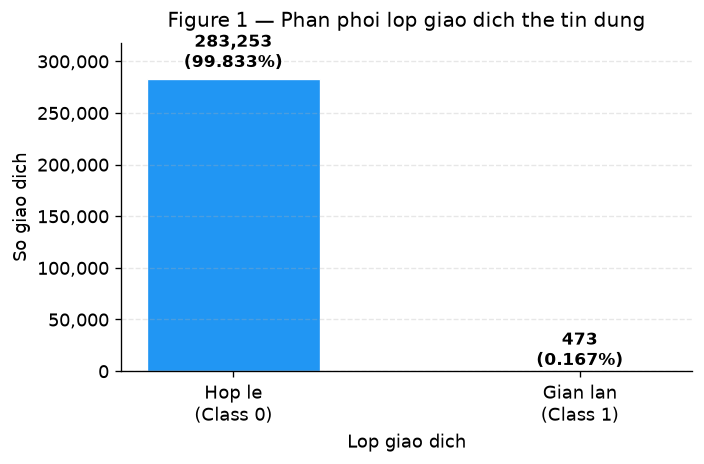

ok Da luu Figure 1.


In [11]:
# 4.1 Phan phoi lop
class_counts = df_clean[TARGET_COL].value_counts().sort_index()
class_pct    = (df_clean[TARGET_COL].value_counts(normalize=True).sort_index() * 100).round(4)

class_df = pd.DataFrame({
    "Nhan":    ["Hop le (0)", "Gian lan (1)"],
    "So luong": class_counts.values,
    "Ti le (%)": class_pct.values,
})
display(class_df)

print(f'\nTi le gian lan: {class_pct[1]:.4f}%')
print(f'Ti le mat can bang (legit:fraud) approx {class_counts[0]/class_counts[1]:.0f}:1')

# Figure 1 — Class Distribution (paper figure)
fig, ax = plt.subplots(figsize=(6, 4))

bars = ax.bar(
    ["Hop le\n(Class 0)", "Gian lan\n(Class 1)"],
    class_counts.values,
    color=["#2196F3", "#F44336"],
    width=0.5,
    edgecolor="white",
    linewidth=0.8,
)

for bar, cnt, pct in zip(bars, class_counts.values, class_pct.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() * 1.02,
        f'{cnt:,}\n({pct:.3f}%)',
        ha="center", va="bottom", fontsize=10, fontweight="bold",
    )

ax.set_ylabel("So giao dich", fontsize=11)
ax.set_xlabel("Lop giao dich", fontsize=11)
ax.set_title("Figure 1 — Phan phoi lop giao dich the tin dung", fontsize=12, pad=10)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax.set_ylim(0, class_counts[0] * 1.12)
ax.grid(axis='y', alpha=0.3, linestyle='--')
plt.tight_layout()

fig.savefig(FIGURES_PAPER / "fig1_class_distribution.png", dpi=200, bbox_inches="tight")
fig.savefig(FIGURES_PAPER / "fig1_class_distribution.pdf", bbox_inches="tight")
fig.savefig(FIGURES_EXP   / "class_distribution.png",     dpi=150, bbox_inches="tight")
plt.show()
print('ok Da luu Figure 1.')

**Nhận xét:** Dataset này có sự mất cân bằng nghiêm trọng.
Giao dịch gian lận chiếm chưa đến 0.2% tổng số giao dịch.
Một mô hình dự đoán tất cả là 'hợp lệ' sẽ đạt accuracy > 99%
nhưng không phát hiện được gian lận nào.
Vì vậy, cần các chiến lược xử lý mất cân bằng và độ đo phù hợp như F2, Precision–Recall.

**Lưu ý:** Các cột V1–V28 là kết quả của phép biến đổi PCA để ẩn danh hóa.
Chúng không đại diện trực tiếp cho các thuộc tính cụ thể của khách hàng hay giao dịch.

### 4.2 Thống Kê `Amount` theo Lớp

**Câu hỏi:** Giá trị giao dịch có khác nhau giữa giao dịch hợp lệ và gian lận không?

Sự khác biệt về số tiền giao dịch có thể là tín hiệu phân biệt hữu ích cho mô hình.

Thong ke Amount theo lop:


,count,mean,std,min,25%,50%,75%,max
Hop le (0),283253.0,88.41,250.38,0.0,5.67,22.00,77.46,25691.16
Gian lan (1),473.0,123.87,260.21,0.0,1.00,9.82,105.89,2125.87


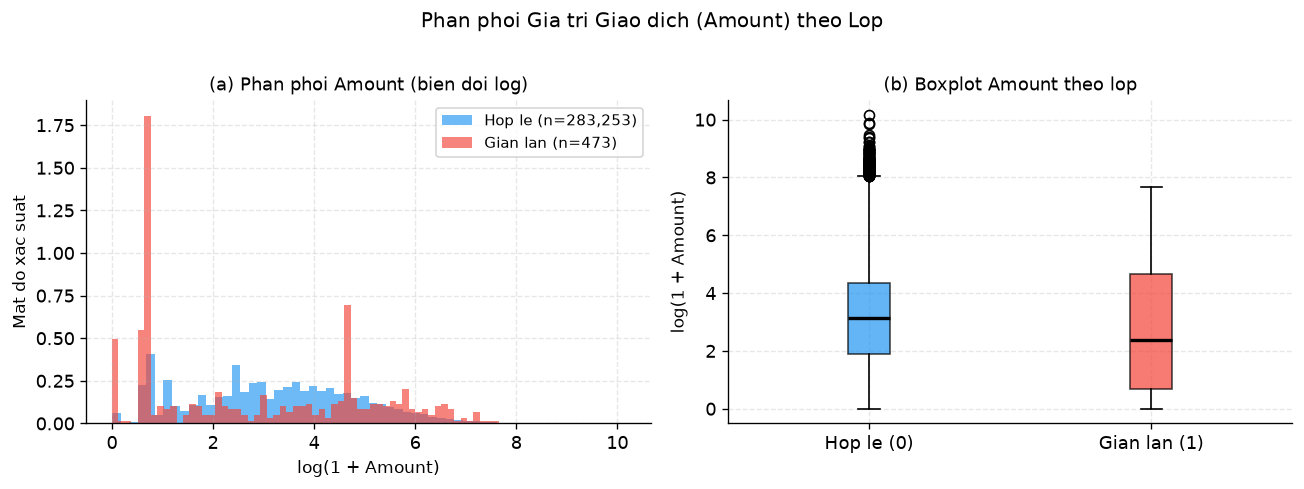

In [12]:
# 4.2 Thong ke Amount theo lop
amount_stats = df_clean.groupby(TARGET_COL)['Amount'].describe().round(2)
amount_stats.index = ["Hop le (0)", "Gian lan (1)"]
print('Thong ke Amount theo lop:')
display(amount_stats)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for cls, label, color in [(0, 'Hop le', '#2196F3'), (1, 'Gian lan', '#F44336')]:
    subset = df_clean[df_clean[TARGET_COL] == cls]['Amount']
    axes[0].hist(
        np.log1p(subset), bins=60, alpha=0.65,
        label=f'{label} (n={len(subset):,})', color=color, density=True,
    )
axes[0].set_xlabel('log(1 + Amount)', fontsize=10)
axes[0].set_ylabel('Mat do xac suat', fontsize=10)
axes[0].set_title('(a) Phan phoi Amount (bien doi log)', fontsize=11)
axes[0].legend(fontsize=9)
axes[0].grid(alpha=0.3, linestyle='--')

data_box = [
    np.log1p(df_clean[df_clean[TARGET_COL] == 0]['Amount']),
    np.log1p(df_clean[df_clean[TARGET_COL] == 1]['Amount']),
]
bp = axes[1].boxplot(data_box, patch_artist=True,
                     tick_labels=['Hop le (0)', 'Gian lan (1)'],
                     medianprops=dict(color='black', linewidth=2))
bp['boxes'][0].set_facecolor('#2196F3')
bp['boxes'][0].set_alpha(0.7)
bp['boxes'][1].set_facecolor('#F44336')
bp['boxes'][1].set_alpha(0.7)
axes[1].set_ylabel('log(1 + Amount)', fontsize=10)
axes[1].set_title('(b) Boxplot Amount theo lop', fontsize=11)
axes[1].grid(alpha=0.3, linestyle='--')

plt.suptitle('Phan phoi Gia tri Giao dich (Amount) theo Lop', fontsize=12, y=1.01)
plt.tight_layout()
fig.savefig(FIGURES_EXP / "amount_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

**Nhận xét:** Phân phối Amount của hai lớp có thể khác nhau,
nhưng sự chênh lệch (nếu có) chưa đủ để phân loại trực tiếp.
Biến đổi log giúp hiển thị phân phối lệch (right-skewed) rõ hơn.
Giá trị thực tế cần được đọc từ bảng thống kê ở trên.

### 4.3 Phân Tích Đặc Trưng `Time`

**Câu hỏi:** Thời điểm giao dịch có khác nhau giữa hai lớp không?

`Time` là số giây kể từ giao dịch đầu tiên trong dataset.
Đây là thông tin thời gian tương đối, không phải timestamp tuyệt đối.

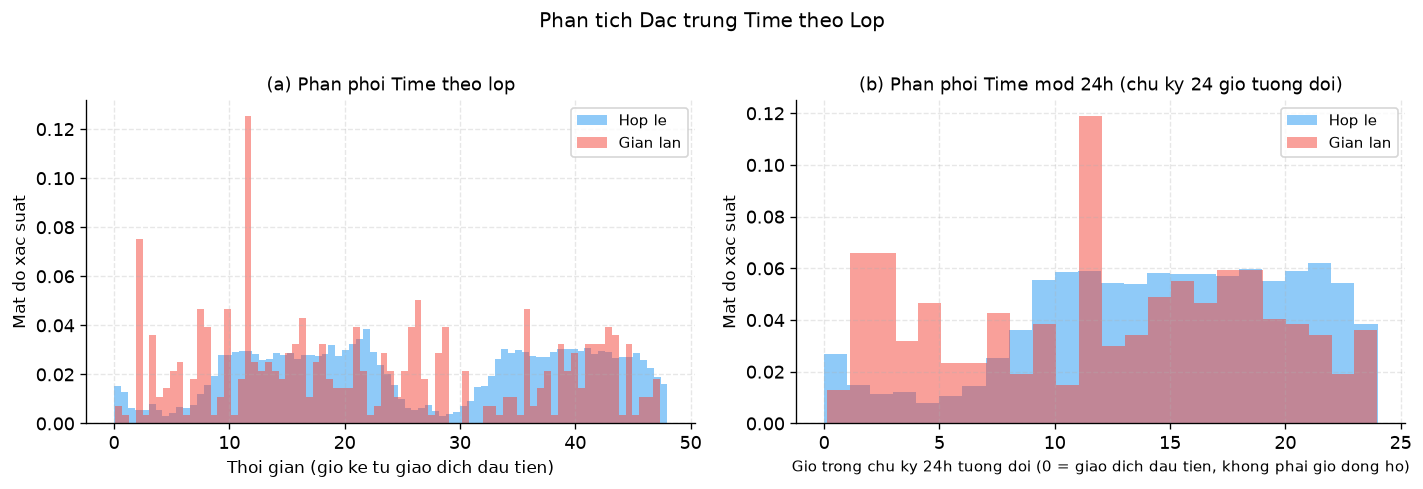

In [13]:
# 4.3 Phan phoi Time theo lop
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for cls, label, color in [(0, 'Hop le', '#2196F3'), (1, 'Gian lan', '#F44336')]:
    subset = df_clean[df_clean[TARGET_COL] == cls]['Time'] / 3600
    axes[0].hist(subset, bins=80, alpha=0.5, label=label, color=color, density=True)
axes[0].set_xlabel('Thoi gian (gio ke tu giao dich dau tien)', fontsize=10)
axes[0].set_ylabel('Mat do xac suat', fontsize=10)
axes[0].set_title('(a) Phan phoi Time theo lop', fontsize=11)
axes[0].legend(fontsize=9)
axes[0].grid(alpha=0.3, linestyle='--')

# Time chi la so giay ke tu giao dich dau tien, khong co moc gio dong ho.
# Phep mod 24h chi gap truc thoi gian theo chu ky 24 gio tuong doi, khong cho biet gio trong ngay.
for cls, label, color in [(0, 'Hop le', '#2196F3'), (1, 'Gian lan', '#F44336')]:
    subset = (df_clean[df_clean[TARGET_COL] == cls]['Time'] % (24 * 3600)) / 3600
    axes[1].hist(subset, bins=24, alpha=0.5, label=label, color=color, density=True)
axes[1].set_xlabel('Gio trong chu ky 24h tuong doi (0 = giao dich dau tien, khong phai gio dong ho)', fontsize=9)
axes[1].set_ylabel('Mat do xac suat', fontsize=10)
axes[1].set_title('(b) Phan phoi Time mod 24h (chu ky 24 gio tuong doi)', fontsize=11)
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.3, linestyle='--')

plt.suptitle('Phan tich Dac trung Time theo Lop', fontsize=12, y=1.01)
plt.tight_layout()
fig.savefig(FIGURES_EXP / "time_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

**Nhận xét:** Đặc trưng `Time` phản ánh mẫu thời gian tương đối của giao dịch.
Biểu đồ (b) gập `Time` theo chu kỳ 24 giờ tính từ giao dịch đầu tiên (dataset kéo dài khoảng 48 giờ, nên mỗi vị trí trong chu kỳ gồm hai lần lặp).
Vì `Time` không có mốc đồng hồ, trục hoành của biểu đồ này không phải giờ trong ngày và không cho biết giao dịch xảy ra lúc mấy giờ.
Nếu giao dịch gian lận tập trung vào một số thời điểm nhất định,
đây có thể là tín hiệu hữu ích cho mô hình.
Tuy nhiên, vì ta dùng chia ngẫu nhiên (stratified random split) chứ không chia theo thời gian,
ta không thể suy luận về khả năng tổng quát hóa theo thời gian tuyến tính.
Ta giữ `Time` như một đặc trưng thông thường và chuẩn hóa nó cùng với `Amount` trong Notebook B.

### 4.4 So Sánh Phân Phối Đặc Trưng V

**Câu hỏi:** Các đặc trưng V1–V28 có phân phối khác nhau giữa hai lớp không?

Ta chọn một số đặc trưng đại diện dựa trên sự khác biệt thống kê (Cohen's d xấp xỉ).

6 dac trung V khac biet lon nhat (Cohen's d xap xi):
  V17: 7.685
  V14: 7.191
  V12: 6.145
  V10: 5.073
  V16: 4.588
  V3: 4.469


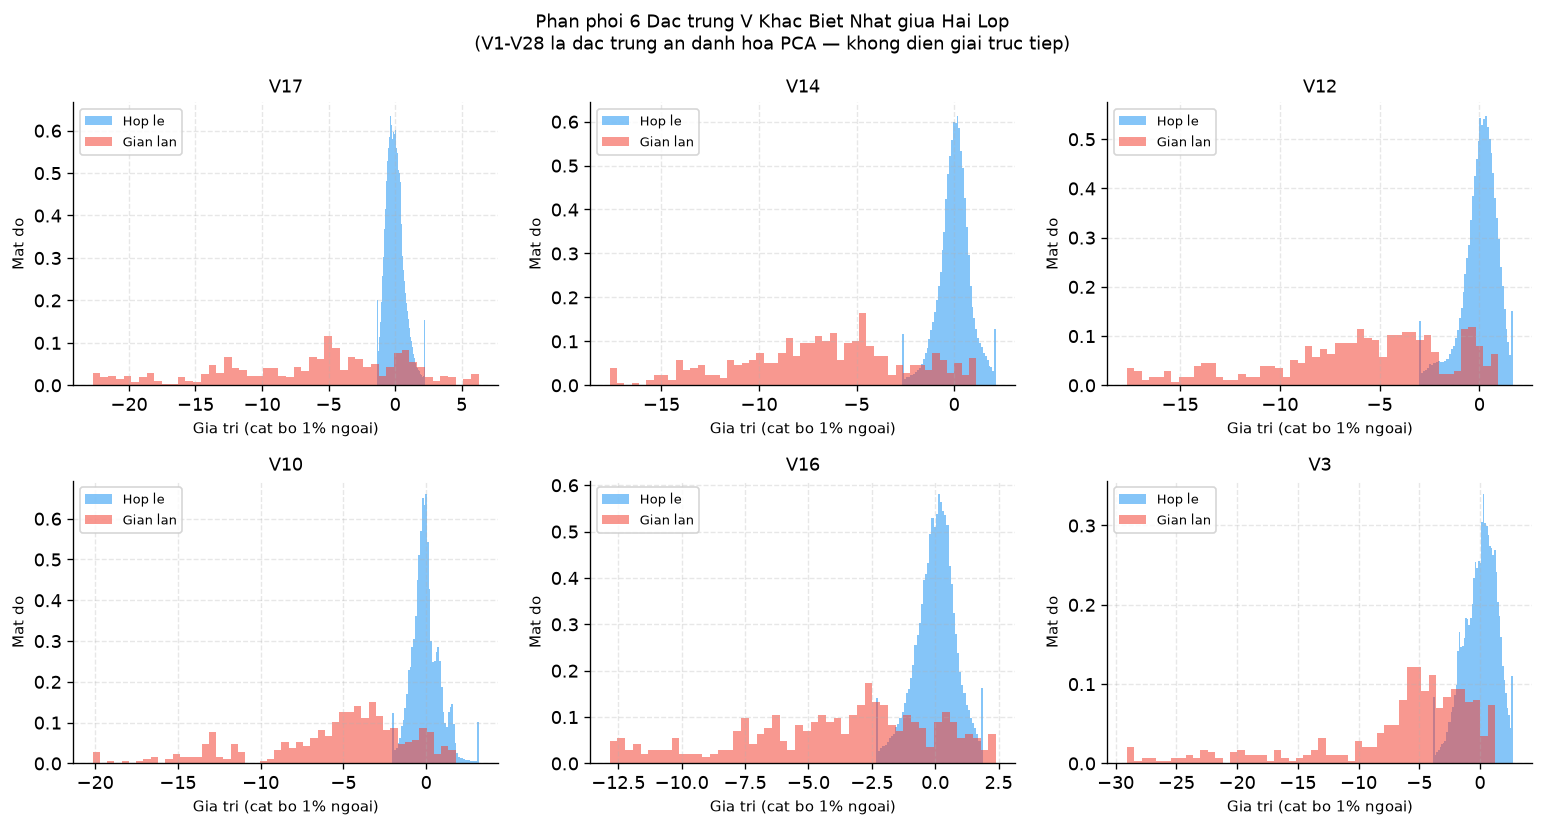

In [14]:
# 4.4 So sanh phan phoi dac trung V
v_cols = [c for c in df_clean.columns if c.startswith('V')]
fraud   = df_clean[df_clean[TARGET_COL] == 1]
legit   = df_clean[df_clean[TARGET_COL] == 0]

diffs = {}
for c in v_cols:
    pooled_std = df_clean[c].std()
    if pooled_std > 0:
        diffs[c] = abs(fraud[c].mean() - legit[c].mean()) / pooled_std

top_features = sorted(diffs, key=diffs.get, reverse=True)[:6]
print(f'6 dac trung V khac biet lon nhat (Cohen\'s d xap xi):')
for f in top_features:
    print(f'  {f}: {diffs[f]:.3f}')

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
axes = axes.flatten()

for ax, feat in zip(axes, top_features):
    for cls, label, color in [(0, 'Hop le', '#2196F3'), (1, 'Gian lan', '#F44336')]:
        subset = df_clean[df_clean[TARGET_COL] == cls][feat]
        q01, q99 = subset.quantile([0.01, 0.99])
        ax.hist(subset.clip(q01, q99), bins=50, alpha=0.55,
                label=label, color=color, density=True)
    ax.set_title(f'{feat}', fontsize=11)
    ax.set_xlabel('Gia tri (cat bo 1% ngoai)', fontsize=9)
    ax.set_ylabel('Mat do', fontsize=9)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3, linestyle='--')

plt.suptitle(
    'Phan phoi 6 Dac trung V Khac Biet Nhat giua Hai Lop\n'
    '(V1-V28 la dac trung an danh hoa PCA — khong dien giai truc tiep)',
    fontsize=11
)
plt.tight_layout()
fig.savefig(FIGURES_EXP / "feature_distributions_top6.png", dpi=150, bbox_inches="tight")
plt.show()

**Nhận xét:** Các đặc trưng V1–V28 là kết quả của phép biến đổi PCA và được ẩn danh hóa.
Ta không thể biết chúng đại diện cho thuộc tính giao dịch cụ thể nào.
Sự khác biệt phân phối giữa hai lớp, nếu có, cho thấy đặc trưng đó
mang tín hiệu phân biệt hữu ích cho mô hình phân loại.
Ta không suy luận nhân quả từ sự tương quan này.

### 4.5 Phân Tích Tương Quan

**Câu hỏi:** Các đặc trưng có tương quan như thế nào với cột Class?

Ma trận tương quan giúp hiểu mối quan hệ tuyến tính.
**Lưu ý quan trọng: Tương quan ≠ Nhân quả.**

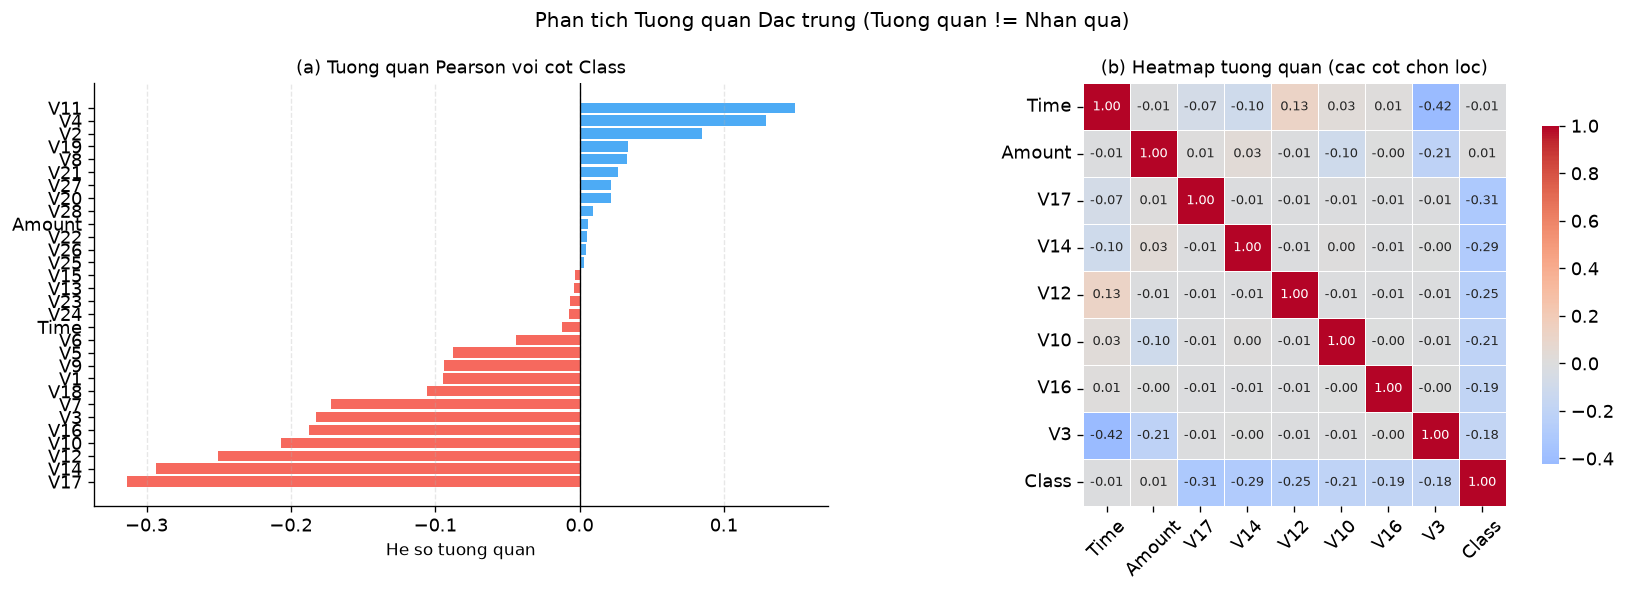

In [15]:
# 4.5 Ma tran tuong quan
corr_with_class = df_clean.corr(numeric_only=True)[TARGET_COL].drop(TARGET_COL).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = ['#F44336' if v < 0 else '#2196F3' for v in corr_with_class.values]
axes[0].barh(corr_with_class.index, corr_with_class.values, color=colors, alpha=0.8)
axes[0].axvline(0, color='black', linewidth=0.8)
axes[0].set_title('(a) Tuong quan Pearson voi cot Class', fontsize=11)
axes[0].set_xlabel('He so tuong quan', fontsize=10)
axes[0].grid(alpha=0.3, linestyle='--', axis='x')

key_cols = ['Time', 'Amount'] + top_features + [TARGET_COL]
corr_sub = df_clean[key_cols].corr()
sns.heatmap(
    corr_sub, ax=axes[1], cmap='coolwarm', center=0,
    annot=True, fmt='.2f', annot_kws={'size': 8},
    linewidths=0.5, square=True, cbar_kws={'shrink': 0.8},
)
axes[1].set_title('(b) Heatmap tuong quan (cac cot chon loc)', fontsize=11)
axes[1].tick_params(axis='x', rotation=45)
axes[1].tick_params(axis='y', rotation=0)

plt.suptitle('Phan tich Tuong quan Dac trung (Tuong quan != Nhan qua)', fontsize=12)
plt.tight_layout()
fig.savefig(FIGURES_EXP / "correlation_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

**Nhận xét:** Tương quan Pearson đo mối quan hệ tuyến tính tổng thể.
Các đặc trưng V có tương quan gần 0 với nhau (đây là tính chất của PCA),
nhưng một số có tương quan đáng kể với cột `Class`.
Ta không suy luận nhân quả từ các tương quan này.

---
## Phần 5 — Chiến Lược Chuẩn Bị Dữ Liệu

### 5.1 Tách Đặc Trưng và Nhãn

Ta tách dataset thành:
- `X`: ma trận đặc trưng đầu vào (tất cả cột trừ `Class`)
- `y`: vector nhãn mục tiêu (cột `Class`)

Cột `Class` **không** được dùng làm đặc trưng đầu vào.

In [16]:
# 5.1 Tach X va y
feature_cols = [c for c in df_clean.columns if c != TARGET_COL]
X = df_clean[feature_cols].copy()
y = df_clean[TARGET_COL].copy()

print(f'Dac trung X: {X.shape}  ({len(feature_cols)} cot)')
print(f'Nhan y:      {y.shape}')
print(f'\nDanh sach cot dac trung ({len(feature_cols)} cot):')
print(feature_cols)
print(f'\nPhan phoi nhan:')
print(y.value_counts().to_string())

Dac trung X: (283726, 30)  (30 cot)
Nhan y:      (283726,)

Danh sach cot dac trung (30 cot):
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']

Phan phoi nhan:
Class
0    283253
1       473


### 5.2 Chia Tập Dữ Liệu (Stratified Split)

**Tại sao cần Stratified Split?**

Vì gian lận rất hiếm (~0.17%), nếu chia ngẫu nhiên không phân tầng,
một tập nhỏ có thể không chứa đủ mẫu gian lận để huấn luyện và đánh giá.
Stratified split đảm bảo tỉ lệ lớp trong mỗi tập gần giống tỉ lệ gốc.

**Thực hiện bằng hai bước:**
1. Chia train (70%) và temp (30%)
2. Chia temp thành validation (15%) và test (15%)

> **Quan trọng:** Chia ngẫu nhiên kiểm tra tổng quát hóa trên cùng phân phối dữ liệu.
> Nó không kiểm tra tổng quát hóa theo thời gian hay trên ngân hàng khác.

In [17]:
# 5.2 Chia train / validation / test
# Buoc 1: Tach train (70%) va temp (30%)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=(VAL_RATIO + TEST_RATIO),
    stratify=y,
    random_state=RANDOM_SEED,
)

# Buoc 2: Chia temp thanh validation va test (50/50 cua 30%)
val_relative = VAL_RATIO / (VAL_RATIO + TEST_RATIO)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=(1 - val_relative),
    stratify=y_temp,
    random_state=RANDOM_SEED,
)

print(f"{'Tap':<12} {'Kich thuoc':>12} {'Hop le (0)':>12} {'Gian lan (1)':>14} {'% Gian lan':>12}")
print('-' * 64)
for name, y_s in [('Train', y_train), ('Validation', y_val), ('Test', y_test), ('Tong', y)]:
    n = len(y_s)
    n0 = (y_s == 0).sum()
    n1 = (y_s == 1).sum()
    pct = n1 / n * 100
    print(f'{name:<12} {n:>12,} {n0:>12,} {n1:>14,} {pct:>11.4f}%')

print(f'\nKich thuoc dac trung: {X_train.shape[1]} cot')

Tap            Kich thuoc   Hop le (0)   Gian lan (1)   % Gian lan
----------------------------------------------------------------
Train             198,608      198,277            331      0.1667%
Validation         42,559       42,488             71      0.1668%
Test               42,559       42,488             71      0.1668%
Tong              283,726      283,253            473      0.1667%

Kich thuoc dac trung: 30 cot


In [18]:
# 5.3 Kiem tra khong chong cheo chi so hang
idx_train = set(X_train.index)
idx_val   = set(X_val.index)
idx_test  = set(X_test.index)

overlap_tv = idx_train & idx_val
overlap_tt = idx_train & idx_test
overlap_vt = idx_val   & idx_test

print('Kiem tra chong cheo chi so hang:')
print(f'  Train AND Val:   {len(overlap_tv)} dong {"ok" if not overlap_tv else "LOI"}')
print(f'  Train AND Test:  {len(overlap_tt)} dong {"ok" if not overlap_tt else "LOI"}')
print(f'  Val   AND Test:  {len(overlap_vt)} dong {"ok" if not overlap_vt else "LOI"}')
n_total = len(idx_train) + len(idx_val) + len(idx_test)
print(f'  Tong = Train + Val + Test: {n_total} == {len(df_clean)} {"ok" if n_total == len(df_clean) else "LOI"}')

assert list(X_train.columns) == list(X_val.columns) == list(X_test.columns), 'Cot khong khop!'
print('\nok Tat ca kiem tra qua.')

Kiem tra chong cheo chi so hang:
  Train AND Val:   0 dong ok
  Train AND Test:  0 dong ok
  Val   AND Test:  0 dong ok
  Tong = Train + Val + Test: 283726 == 283726 ok

ok Tat ca kiem tra qua.


---
## Phần 6 — Phòng Ngừa Rò Rỉ Dữ Liệu và Kế Hoạch Tiền Xử Lý

### Rò Rỉ Dữ Liệu (Data Leakage) là gì?

**Data leakage** xảy ra khi thông tin từ tập validation/test rò rỉ vào quá trình
huấn luyện, khiến đánh giá mô hình lạc quan hơn thực tế.

### Các Quy Tắc Phòng Ngừa trong Dự Án Này

| Bước | Quy tắc |
|---|---|
| Scaling (chuẩn hóa) | Fit scaler **chỉ** trên train, transform trên val/test |
| SMOTE / Resampling | Áp dụng **chỉ** trên train, không bao giờ trên val/test |
| Feature selection | Fit **chỉ** trên train |
| Tất cả preprocessing | Dùng **Pipeline** của scikit-learn / imbalanced-learn |

### Về Đặc Trưng `Time`

`Time` là số giây kể từ giao dịch đầu tiên. Đây là đặc trưng thời gian tương đối.
Ta giữ lại `Time` vì: (1) nó có thể mang tín hiệu về mẫu thời gian của giao dịch,
(2) không có bằng chứng rò rỉ khi chia ngẫu nhiên.
Ta sẽ chuẩn hóa `Time` cùng với `Amount` bằng StandardScaler trong Notebook B.

### Pipeline Sẽ Dùng trong Notebook B

```python
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

# Vi du pipeline voi SMOTE (toan bo preprocessing nam trong pipeline):
pipe = ImbPipeline([
    ('scaler', StandardScaler()),    # Fit chi tren train
    ('smote',  SMOTE(random_state=42)),  # Apply chi tren train
    ('clf',    LogisticRegression()),
])
pipe.fit(X_train, y_train)
# Khi predict tren val/test, pipeline chi transform (khong fit lai)
```

---
## Phần 7 — Lưu Dữ Liệu Đã Chuẩn Bị và Manifest

Ta lưu 6 file CSV và 1 file manifest JSON để Notebook B có thể nạp và xác minh.
Giữ nguyên chỉ số hàng (index) để kiểm tra độc lập giữa các tập.

In [19]:
# 7.1 Luu cac file CSV
splits = {
    "X_train":      X_train,
    "y_train":      y_train.to_frame(),
    "X_validation": X_val,
    "y_validation": y_val.to_frame(),
    "X_test":       X_test,
    "y_test":       y_test.to_frame(),
}

for name, data in splits.items():
    path = PROCESSED_DIR / f'{name}.csv'
    data.to_csv(path, index=True)
    print(f'ok Da luu: {path.name}  ({data.shape})')

ok Da luu: X_train.csv  ((198608, 30))
ok Da luu: y_train.csv  ((198608, 1))
ok Da luu: X_validation.csv  ((42559, 30))
ok Da luu: y_validation.csv  ((42559, 1))
ok Da luu: X_test.csv  ((42559, 30))
ok Da luu: y_test.csv  ((42559, 1))


In [20]:
# 7.2 Tao va luu manifest
manifest = {
    "created_at":            datetime.datetime.now(datetime.timezone.utc).isoformat(),
    "dataset_source":        "https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud",
    "dataset_filename":      DATA_PATH.name,
    "dataset_checksum_md5":  checksum,
    "random_seed":           RANDOM_SEED,
    "target_column":         TARGET_COL,
    "feature_columns":       feature_cols,
    "n_features":            len(feature_cols),
    "split_proportions": {
        "train":      TRAIN_RATIO,
        "validation": VAL_RATIO,
        "test":       TEST_RATIO,
    },
    "dataset_dimensions": {
        "total_rows": int(len(df_clean)),
        "total_cols": int(df_clean.shape[1]),
    },
    "class_counts": {
        "total": {
            "legitimate": int((y == 0).sum()),
            "fraud":      int((y == 1).sum()),
        },
        "train": {
            "rows":       int(len(y_train)),
            "legitimate": int((y_train == 0).sum()),
            "fraud":      int((y_train == 1).sum()),
        },
        "validation": {
            "rows":       int(len(y_val)),
            "legitimate": int((y_val == 0).sum()),
            "fraud":      int((y_val == 1).sum()),
        },
        "test": {
            "rows":       int(len(y_test)),
            "legitimate": int((y_test == 0).sum()),
            "fraud":      int((y_test == 1).sum()),
        },
    },
    "data_cleaning": dedup_info,
    "preprocessing_notes": (
        "Scaler phai duoc fit chi tren X_train. "
        "Resampling (SMOTE, undersampling) chi ap dung tren train. "
        "Val va test phai giu nguyen phan phoi goc."
    ),
}

manifest_path = PROCESSED_DIR / 'manifest.json'
with open(manifest_path, 'w', encoding='utf-8') as f:
    json.dump(manifest, f, indent=2, ensure_ascii=False)

print(f'ok Da luu manifest: {manifest_path}')
print(f'\nNoi dung manifest:')
print(json.dumps(manifest, indent=2, ensure_ascii=False))


ok Da luu manifest: C:\Users\lmlmdf404\Desktop\credit_card_fraud_project\data\processed\manifest.json

Noi dung manifest:
{
  "created_at": "2026-10-29T09:17:36.254199+00:00",
  "dataset_source": "https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud",
  "dataset_filename": "creditcard.csv",
  "dataset_checksum_md5": "e90efcb83d69faf99fcab8b0255024de",
  "random_seed": 42,
  "target_column": "Class",
  "feature_columns": [
    "Time",
    "V1",
    "V2",
    "V3",
    "V4",
    "V5",
    "V6",
    "V7",
    "V8",
    "V9",
    "V10",
    "V11",
    "V12",
    "V13",
    "V14",
    "V15",
    "V16",
    "V17",
    "V18",
    "V19",
    "V20",
    "V21",
    "V22",
    "V23",
    "V24",
    "V25",
    "V26",
    "V27",
    "V28",
    "Amount"
  ],
  "n_features": 30,
  "split_proportions": {
    "train": 0.7,
    "validation": 0.15,
    "test": 0.15
  },
  "dataset_dimensions": {
    "total_rows": 283726,
    "total_cols": 31
  },
  "class_counts": {
    "total": {
      "legitimate": 

### Cách Notebook B Sử Dụng Các Artifacts

Notebook B sẽ:
1. Nạp `manifest.json` và kiểm tra các tham số (seed, tỉ lệ, số đặc trưng)
2. Nạp 6 file CSV từ `data/processed/`
3. Xác minh: số cột khớp, nhãn hợp lệ, kích thước khớp manifest
4. Kiểm tra không chồng chéo chỉ số hàng giữa các tập
5. Chỉ sau khi tất cả kiểm tra qua → tiến hành thí nghiệm RQ1–RQ3

**Dataset thô (`creditcard.csv`) không bao giờ bị ghi đè.**

---
## Phần 8 — Tóm Tắt Notebook A

Notebook A đã hoàn thành các bước sau:

| Bước | Kết quả |
|---|---|
| Kiểm tra môi trường | Xác nhận tất cả thư viện cần thiết |
| Nạp dữ liệu | Đọc `creditcard.csv`, xác minh cấu trúc và nhãn |
| Đánh giá chất lượng | Kiểm tra giá trị thiếu, trùng lặp, vô hạn, nhãn |
| EDA | Phân tích phân phối lớp, Amount, Time, và các đặc trưng V |
| Chia tập dữ liệu | Stratified split 70/15/15 với RANDOM_SEED cố định |
| Kế hoạch tiền xử lý | Giải thích phòng ngừa rò rỉ dữ liệu |
| Lưu artifacts | 6 file CSV, manifest.json, và các hình vẽ EDA |

**Kết quả quan trọng:**
- Dataset có mất cân bằng nghiêm trọng (xem Figure 1)
- Không có giá trị thiếu hay vô hạn
- Tập train/val/test không chồng chéo, stratified theo nhãn

> **Bước tiếp theo:** Chạy `Notebook_B_Experiments.ipynb` để thực hiện thí nghiệm RQ1–RQ3.

In [21]:
# 8. Danh sach artifacts da tao
import os

print('=' * 60)
print('DANH SACH ARTIFACTS DA TAO — NOTEBOOK A')
print('=' * 60)

for dir_path, label in [
    (PROCESSED_DIR, 'data/processed/'),
    (FIGURES_PAPER, 'results/figures/paper/'),
    (FIGURES_EXP,   'results/figures/exploratory/'),
]:
    if dir_path.exists():
        files = sorted(f for f in os.listdir(dir_path) if os.path.isfile(dir_path / f))
        if files:
            print(f'\n{label}')
            for fname in files:
                fpath = dir_path / fname
                size = fpath.stat().st_size / 1024
                print(f'  {fname:<45} {size:>8.1f} KB')

print('\nok Notebook A hoan tat. Chay Notebook B de thuc hien thi nghiem.')

DANH SACH ARTIFACTS DA TAO — NOTEBOOK A

data/processed/
  X_test.csv                                     22241.0 KB
  X_train.csv                                   103797.8 KB
  X_validation.csv                               22242.4 KB
  manifest.json                                      1.8 KB
  y_test.csv                                       399.2 KB
  y_train.csv                                     1863.8 KB
  y_validation.csv                                 399.3 KB

results/figures/paper/
  fig1_class_distribution.pdf                       20.1 KB
  fig1_class_distribution.png                       53.0 KB
  fig2_imbalance_comparison.pdf                     28.1 KB
  fig2_imbalance_comparison.png                    133.0 KB
  fig3_threshold_optimization.pdf                   23.2 KB
  fig3_threshold_optimization.png                  152.7 KB
  fig4_test_confusion_matrix.pdf                    28.9 KB
  fig4_test_confusion_matrix.png                    91.7 KB
  fig5_test_pr_curv